Order of Events
1. Planning
    - Get coordinates of environment (from Vision)
    - Compute visibility graph and path (from Global Nav)
3. Motion
    - Start following path
    - Continuously correct route with Kalman filter (from Kalman)
4. Local Navigation
    - Add extra obstacle in path
    - Avoid obstacle (from Local Nav)
5. Success
    - Reach Goal

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw
import math
# from VisibilityGraph import *
from kalman_filter import *
from Vision import *

In [2]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node fd9ca6c7-db66-4fb2-8acb-453c18d98ce5

In [3]:
# Global Nav Variables as standin for input from Vision

ob1 = [(176, 206), (215, 217), (194, 294), (155, 283)]
ob2 = [(522, 440), (562, 440), (562, 520), (522, 520)]
ob3 = [(870, 267), (909, 256), (930, 333), (891, 344)]

start = (1, 1)
goal = (1000, 700)
raw_obstacles = (ob1, ob2, ob3)

5
[0, 5, 9, 11, 1] [array([1., 1.]), array([355.94549682, 137.26709127]), array([677., 325.]), array([810.57377468, 486.17108677]), array([1000.,  700.])]


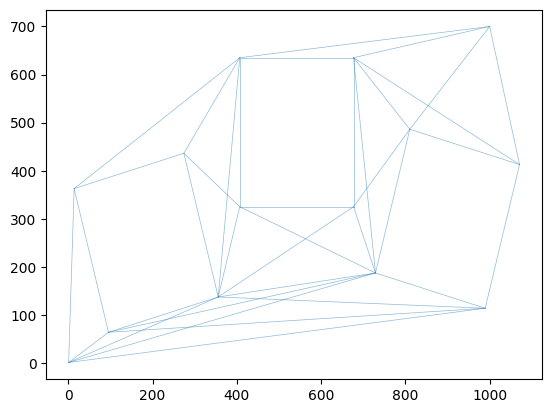

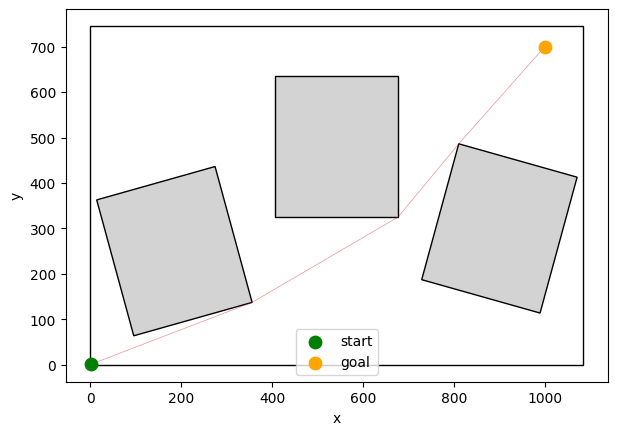

In [4]:
path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

In [ ]:
# def compute_heading(a, b, prev_heading):
#     distance = np.linalg.norm(a - b, ord=2)
    
#     dx = b[0] - a[0]
#     dy = b[1] - a[1]
#     heading = math.atan(dy/dx) - prev_heading
#     prev_heading = math.atan(dy/dx)

#     return distance, heading, prev_heading

In [5]:
def wrap_angle(angle):
    """Wrap angle to [-pi, pi]."""
    return math.atan2(math.sin(angle), math.cos(angle))

def compute_heading(a, b, prev_heading):
    dx = b[0] - a[0]
    dy = b[1] - a[1]

    distance = math.hypot(dx, dy)
    abs_heading = math.atan2(dy, dx)          # absolute heading of this segment
    turn = wrap_angle(abs_heading - prev_heading)  # signed turn needed from current heading

    return distance, turn, abs_heading

In [6]:
SPEED_TO_MM_S = 0.335   
WHEEL_BASE = 95.0

async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def forward(v, d): # [mm/s, mm]
    T = d/v
    thymio_v = v/SPEED_TO_MM_S
    
    try:
        await set_speed(thymio_v, thymio_v)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)
        
async def turn(v, theta): # [rad/s, rad]

    arc = abs(theta) * WHEEL_BASE / 2 
    T = arc / v                          
    thymio_v =  abs(v) / SPEED_TO_MM_S         
    direction = 1 if theta > 0 else -1
    try:
        await set_speed(-direction * thymio_v, direction * thymio_v)
        await client.sleep(T)
    finally:
        await set_speed(0, 0)

In [8]:
v = 100
prev_heading = 0

for i in range(len(path)-1):
    distance, heading, prev_heading = compute_heading(coords[i], coords[i+1], prev_heading)
    print(distance, heading, prev_heading)
    await turn(v, heading)
    await forward(v, distance)




380.2039267000356 0.36655911959135123 0.36655911959135123
371.9134832599238 0.16256305603468935 0.5291221756260406
209.32766776700072 0.34963499266169107 0.8787571682877316
285.66606198903224 -0.03291844629711127 0.8458387219906204


In [ ]:
await forward(100, 10)

In [26]:
await turn(100, np.pi)

Obstacles detected: 2


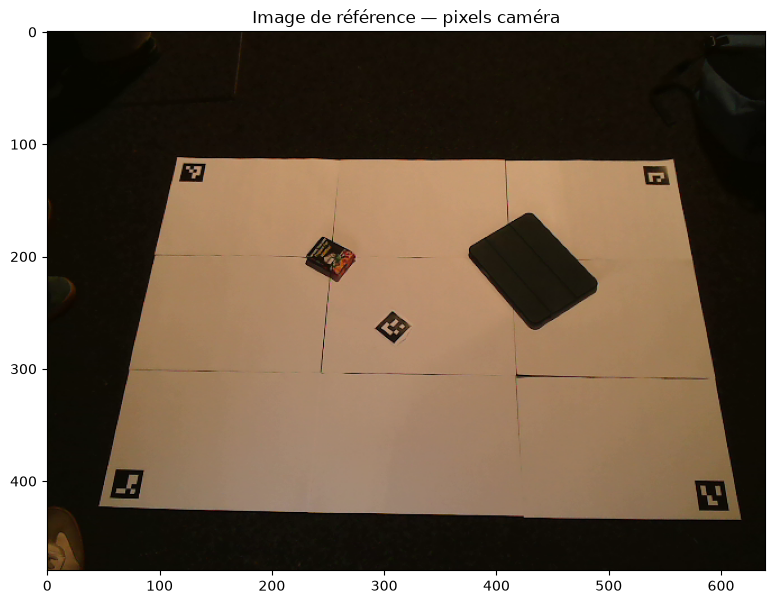

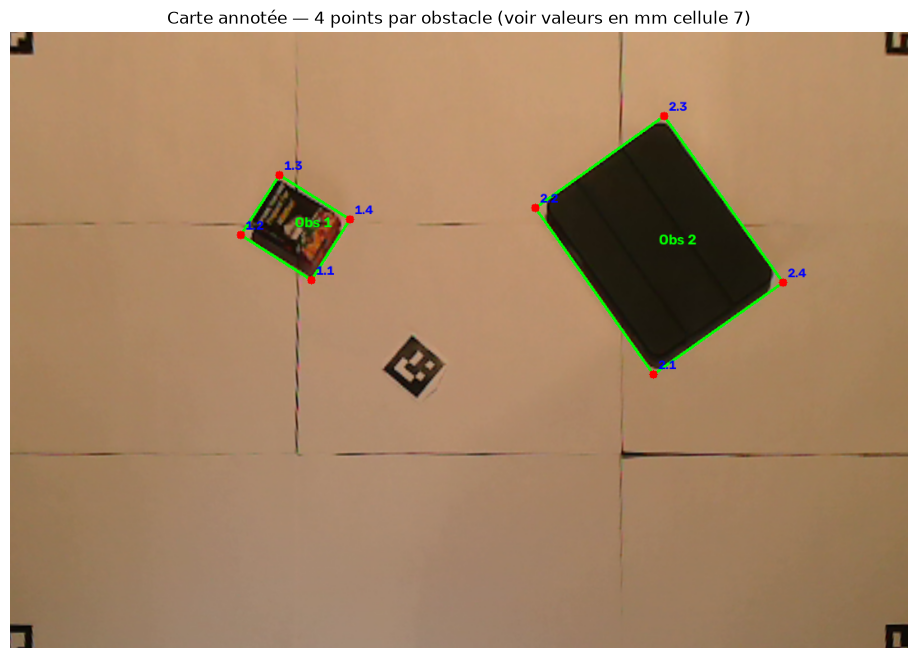

Image enregistrée : C:\Robotics\Projet BMR Vision\mobile_robotics\navigation_annotated.png


In [2]:
initialize_vision(True)

In [3]:
get_obstacles_pose()


[2,
 [(367.31, 448.98), (281.43, 503.65), (328.04, 576.93), (413.92, 522.26)],
 [(785.06, 333.53), (640.35, 537.11), (798.11, 649.33), (942.81, 445.76)]]